[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch37_LabCh37_Masked_vs_Causal.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 37: Three Families: BERT, GPT and T5** (Part VIII: Language Models).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=37](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=37)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch37 - Masked vs Causal
## Pretrain a tiny encoder by filling in blanks, then put it to work with a handful of labels

This lab goes with **Chapter 37** of *The Why Book of Deep Learning, Part 2*.

Chapter 35 built a decoder: a stack of blocks with a causal mask, asked "what comes next?" at every position.
Take away one argument, the mask, and the same stack becomes an **encoder**: every position sees every other
position. It can no longer be asked what comes next (it can see what comes next), so it is asked something
else: *some words have been hidden; what were they?* That is masked-token prediction, the pretraining task of
BERT (2018).

In this lab you build that encoder from the blocks of Chapter 35, look at the two masks side by side, pretrain
the encoder on film reviews **without using a single label**, read what it guesses for a few blanks, and then
ask the question the whole pretraining idea rests on: *with only a few labelled reviews, does the pretrained
encoder make a better sentiment classifier than the same network started from random weights?*

| The encoder of this lab | value |
|---|---|
| kind | encoder-only, pre-norm, no causal mask |
| width d | 64 |
| heads | 4 (each 16 wide) |
| blocks | 2 (the same block as TinyGPT: 49,984 weights each) |
| feed-forward width | 256 |
| sequence length T | 64 words |
| vocabulary V | 2,000 word ids |
| pretraining head | tied to the token table (as in BERT) |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Draw the full mask and the causal mask, and prove which one a model has | Steps 3 and 6 |
| Count an encoder's parameters by hand and check the count against Keras | Steps 4, 5 and 8 |
| Write the masking rule of BERT (choose 15%; then 80 / 10 / 10) | Step 7 |
| Check a masked model's first loss against ln V and against a frequency table | Step 9 |
| Pretrain with masked-token prediction and read the guesses | Steps 10 to 13 |
| Fine-tune a pretrained encoder and compare it fairly with training from scratch | Steps 14 to 17 |
| Say how much training signal a masked model gets per sequence, and count BERT-base | Steps 18 and 19 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about five minutes on a laptop CPU. Step 10 (pretraining) takes two to three minutes and
> Steps 15 to 17 (fourteen short training runs) about a minute and a half. No GPU is needed. The only download
> is the IMDB data set that ships with Keras.

> **Honest scale:** this is a miniature. The encoder has about a quarter of a million weights and is pretrained
> for two minutes on 1.3 million words. BERT-base has about 110 million weights and was pretrained for days on
> about 3.3 billion words. The lab shows the *mechanism* and a small real gain. It does not show the size of
> gain a full-size pretrained model gives.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 37
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The data: the first 64 words of each review

Chapter 35 read IMDB one character at a time. A sentiment classifier needs to see words, so this lab uses a
word-level vocabulary, kept small on purpose:

* the **1,995 commonest words** keep their own id (ids 4 to 1,998, commonest first: id 4 is `the`);
* every other word becomes id 2, **unknown**;
* id 1 is the **start** token that Keras puts in front of every review;
* id 1,999 is ours: the **mask** token. It never occurs in the text.

That makes V = 2,000 ids (ids 0 and 3 exist but are never used). The leftover `br` tokens (they were HTML line
breaks) are removed, as in Chapter 35. Each review is then cut to its first **64 tokens** (the start token and
63 words). Reviews shorter than that are dropped, so there is no padding to worry about.

The training split gives us text for pretraining. Its labels stay in a drawer until Step 14.

> **Predict:** with only 1,995 known words, what fraction of the words in a review will be "unknown": about
> 2%, about 15%, or about 40%?

In [2]:
T = 64                      # tokens per sequence
V = 2000                    # ids 0..1999
START, UNKNOWN, MASK = 1, 2, 1999
FIRST_WORD = 4              # id of the commonest word


def load_imdb_words(context=T):
    """IMDB as word ids, without the `br` tokens, cut to the first `context` tokens. Shorter reviews are dropped."""
    (x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=MASK)
    br = keras.datasets.imdb.get_word_index()["br"] + 3            # what is left of HTML line breaks

    def cut(xs, ys):
        xs = [[t for t in r if t != br] for r in xs]
        keep = [i for i, r in enumerate(xs) if len(r) >= context]
        return np.array([xs[i][:context] for i in keep], dtype=np.int32), ys[keep].astype("float32")

    return cut(x_train, y_train), cut(x_test, y_test)


word_index = keras.datasets.imdb.get_word_index()
id_to_word = {i + 3: w for w, i in word_index.items() if i + 3 < MASK}
id_to_word.update({0: "[PAD]", START: "[START]", UNKNOWN: "[?]", MASK: "[MASK]"})
word_to_id = {w: i for i, w in id_to_word.items()}


def decode(ids):
    """ids -> text."""
    return " ".join(id_to_word.get(int(i), "[?]") for i in ids)


(x_all, y_all), (x_test_all, y_test_all) = load_imdb_words()
X_pre, y_pre = x_all[:20000], y_all[:20000]          # text for pretraining (labels unused until Step 14)
X_held = x_all[20000:22000]                           # text the pretraining never sees
X_test, y_test = x_test_all[:4000], y_test_all[:4000]

print("training split:", x_all.shape, " test split:", x_test_all.shape)
print(f"pretraining text: {X_pre.shape[0]:,} reviews x {T} tokens = {X_pre.size:,} tokens")
print(f"unknown words: {(X_pre == UNKNOWN).mean():.1%} of all tokens")
print(f"positive reviews among the first 1,000: {y_pre[:1000].mean():.1%}")
print()
print(decode(X_pre[0]))

training split: (23836, 64)  test split: (23693, 64)
pretraining text: 20,000 reviews x 64 tokens = 1,280,000 tokens
unknown words: 16.2% of all tokens
positive reviews among the first 1,000: 49.3%

[START] this film was just brilliant casting location scenery story direction [?] really [?] the part they played and you could just imagine being there robert [?] is an amazing actor and now the same being director [?] father came from the same [?] island as myself so i loved the fact there was a real [?] with this film the witty [?] throughout


### Why we see this

About one word in six is unknown. That is the price of a 2,000-word vocabulary, and the reason real models
use the subword tokenizers of Chapter 33, which never meet an unknown word. For this lab the price is worth
paying: a small vocabulary keeps the token table small and the pretraining fast.

---
## Step 3 - Two masks, as pictures

Inside attention every position scores every other position: a T × T table (Chapter 22). A **mask** is a
second T × T table of yes and no laid over it.

* **Causal mask** (Chapter 35, decoders): row t may look at columns 0 to t. A staircase.
* **Full mask** (this chapter, encoders): every row may look at every column. Not much of a mask: it is what
  attention does when you do nothing.

> **Predict:** for T = 64, how many of the 4,096 cells are open under each mask?

first 6 rows and columns (1 = may look, 0 = hidden)
full:
[[1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]]
causal:
[[1 0 0 0 0 0]
 [1 1 0 0 0 0]
 [1 1 1 0 0 0]
 [1 1 1 1 0 0]
 [1 1 1 1 1 0]
 [1 1 1 1 1 1]]
open cells, full mask  : 4,096 of 4,096
open cells, causal mask: 2,080 of 4,096  (50.8%)


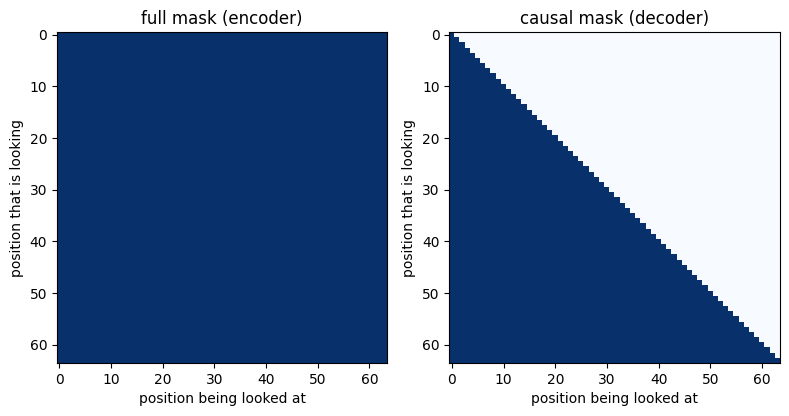

In [3]:
full_mask = np.ones((T, T), dtype=int)
causal_mask = np.tril(np.ones((T, T), dtype=int))
print("first 6 rows and columns (1 = may look, 0 = hidden)")
print("full:");   print(full_mask[:6, :6])
print("causal:"); print(causal_mask[:6, :6])
print(f"open cells, full mask  : {full_mask.sum():,} of {full_mask.size:,}")
print(f"open cells, causal mask: {causal_mask.sum():,} of {causal_mask.size:,}  ({causal_mask.sum() / causal_mask.size:.1%})")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, m, name in [(axes[0], full_mask, "full mask (encoder)"), (axes[1], causal_mask, "causal mask (decoder)")]:
    ax.imshow(m, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(name); ax.set_xlabel("position being looked at"); ax.set_ylabel("position that is looking")
plt.tight_layout(); plt.show()

---
## Step 4 - Count the encoder before building it

The body of the encoder is TinyGPT's body with a different vocabulary: a token table, a position table, two
pre-norm blocks, a final LayerNorm (Chapters 23 and 35).

* **token table:** V rows of d numbers
* **position table:** T rows of d numbers
* **one block:** attention 4d² + 4d, feed-forward (d·ff + ff) + (ff·d + d), two LayerNorms of 2d each
* **final LayerNorm:** 2d

> **Predict:** in TinyGPT (V = 39) the two blocks held over 90% of the weights. With V = 2,000, will the
> blocks still hold most of the model?

In [4]:
def count_encoder(vocab_size=V, d=64, blocks=2, ff=256, context=T):
    """The hand count of the encoder body."""
    attention = 4 * d * d + 4 * d
    feed_forward = (d * ff + ff) + (ff * d + d)
    one_block = attention + feed_forward + 2 * (2 * d)
    parts = {"token table": vocab_size * d, "position table": context * d,
             "blocks": blocks * one_block, "final norm": 2 * d}
    return parts, one_block


parts, one_block = count_encoder()
hand_body = sum(parts.values())
print(f"one block: {one_block:,}  (the same block as TinyGPT)")
for name, n in parts.items():
    print(f"  {name:15s} {n:>8,}   {n / hand_body:6.1%}")
print(f"  {'BODY TOTAL':15s} {hand_body:>8,}")

one block: 49,984  (the same block as TinyGPT)
  token table      128,000    55.1%
  position table     4,096     1.8%
  blocks            99,968    43.1%
  final norm           128     0.1%
  BODY TOTAL       232,192


---
## Step 5 - Build the encoder

`build_encoder()` is Chapter 35's `build_tinygpt()` with two changes: `use_causal_mask` is now an argument
that defaults to **False**, and the function stops at the final LayerNorm, so that different heads can be put
on top (a blank-filling head in Step 8, a sentiment head in Step 14).

Its output is one vector of 64 numbers for every one of the 64 positions.

> **Predict:** will `encoder.count_params()` equal the hand count? And what is the output shape for a batch of
> 4 reviews?

In [5]:
class TokenAndPosition(layers.Layer):
    """ids (batch, T) -> vectors (batch, T, d): a token table plus a learnt position table."""

    def __init__(self, vocab_size, context, d, **kwargs):
        super().__init__(**kwargs)
        init = keras.initializers.RandomNormal(stddev=0.02)
        self.token_table = layers.Embedding(vocab_size, d, embeddings_initializer=init, name="token_table")
        self.position_table = layers.Embedding(context, d, embeddings_initializer=init, name="position_table")

    def call(self, ids):
        positions = keras.ops.arange(keras.ops.shape(ids)[1])
        return self.token_table(ids) + self.position_table(positions)


def build_encoder(vocab_size=V, d=64, heads=4, blocks=2, ff=256, context=T, causal=False, dropout=0.0):
    """Pre-norm transformer body. ids (batch, context) -> vectors (batch, context, d).
    causal=False: an encoder (every position sees every position). causal=True: a decoder body."""
    ids = layers.Input(shape=(context,), dtype="int32", name="ids")
    x = TokenAndPosition(vocab_size, context, d, name="embed")(ids)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, dropout=dropout,
                                      name=f"block{b}_attention")(h, h, use_causal_mask=causal)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = layers.Dense(ff, activation="gelu", name=f"block{b}_ff_wide")(h)
        h = layers.Dense(d, name=f"block{b}_ff_narrow")(h)
        if dropout > 0:
            h = layers.Dropout(dropout, name=f"block{b}_dropout")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    return keras.Model(ids, x, name="encoder")


encoder = build_encoder()
encoder.summary()
print("Keras count:", f"{encoder.count_params():,}", "| hand count:", f"{hand_body:,}")
assert encoder.count_params() == hand_body == 232_192
print("output for 4 reviews:", encoder(X_pre[:4]).shape)

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ids (InputLayer)    │ (None, 64)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed               │ (None, 64, 64)    │    132,096 │ ids[0][0]         │
│ (TokenAndPosition)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_norm1        │ (None, 64, 64)    │        128 │ embed[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attention    │ (None, 64, 64)    │     16,640 │ block1_norm1[0][… │
│ (MultiHeadAttentio… │                   │            │ block1_norm1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add1 (Add)   │ (None, 64, 64)    │          0 │ embed[0][0],      │
│                     │                   │            │ block1_attention… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_norm2        │ (None, 64, 64)    │        128 │ block1_add1[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ff_wide      │ (None, 64, 256)   │     16,640 │ block1_norm2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ff_narrow    │ (None, 64, 64)    │     16,448 │ block1_ff_wide[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add2 (Add)   │ (None, 64, 64)    │          0 │ block1_add1[0][0… │
│                     │                   │            │ block1_ff_narrow… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_norm1        │ (None, 64, 64)    │        128 │ block1_add2[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attention    │ (None, 64, 64)    │     16,640 │ block2_norm1[0][… │
│ (MultiHeadAttentio… │                   │            │ block2_norm1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_add1 (Add)   │ (None, 64, 64)    │          0 │ block1_add2[0][0… │
│                     │                   │            │ block2_attention… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_norm2        │ (None, 64, 64)    │        128 │ block2_add1[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_ff_wide      │ (None, 64, 256)   │     16,640 │ block2_norm2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_ff_narrow    │ (None, 64, 64)    │     16,448 │ block2_ff_wide[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_add2 (Add)   │ (None, 64, 64)    │          0 │ block2_add1[0][0… │
│                     │                   │            │ block2_ff_narrow… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_norm          │ (None, 64, 64)    │        128 │ block2_add2[0][0] │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 232,192 (907.00 KB)

 Trainable params: 232,192 (907.00 KB)

 Non-trainable params: 0 (0.00 B)

Keras count: 232,192 | hand count: 232,192
output for 4 reviews: (4, 64, 64)


### Why we see this

The count matches. Notice how the picture has changed since Chapter 35: the token table alone is now more
than half the model (128,000 of 232,192), and the two blocks, the part that does the thinking, are 43%. A
vocabulary is expensive, even a small one.

---
## Step 6 - Prove which mask a model has

Chapter 35's leak test changed one token and checked that nothing *before* it moved. Run the same test on
two models with **identical weights**: the encoder, and a twin built with `causal=True`.

> **Predict:** change the token at position 40. In the encoder, which output positions move? In the causal
> twin?

In [6]:
def leak_test(model, x, where=40):
    """Change the token at `where`; report how far the outputs move before it and from it onwards."""
    a = np.array(x[:1])
    b = a.copy()
    b[0, where] = (b[0, where] + 1) % MASK
    moved = np.abs(model.predict_on_batch(a) - model.predict_on_batch(b)).max(axis=-1)[0]
    return float(moved[:where].max()), float(moved[where:].max())


causal_twin = build_encoder(causal=True)
causal_twin.set_weights(encoder.get_weights())          # same weights: only the mask differs

for name, m in [("encoder (full mask)", encoder), ("causal twin", causal_twin)]:
    before, after = leak_test(m, X_held)
    print(f"{name:20s} positions 0..39 moved by up to {before:.6f}   positions 40..63 by up to {after:.6f}")
assert leak_test(causal_twin, X_held)[0] < 1e-5 and leak_test(encoder, X_held)[0] > 1e-5

encoder (full mask)  positions 0..39 moved by up to 0.218534   positions 40..63 by up to 1.187005


causal twin          positions 0..39 moved by up to 0.000000   positions 40..63 by up to 0.984637


### Why we see this

In the causal twin, positions 0 to 39 do not move by a single digit: nothing they compute depends on position
40. In the encoder, every position moves: each one is a function of the whole sequence. Two models, the same
232,192 numbers, one argument apart.

That is why an encoder cannot be trained on "what comes next?". The answer to the question at position t is
the input at position t + 1, and the encoder at position t can see it. It needs a question whose answer is
**not in the input**.

---
## Step 7 - The question: hide some words

Masked-token prediction (BERT, 2018), in two rules.

**Rule 1: choose.** Pick about 15% of the positions. We pick exactly **9 of the 64** in every sequence
(15% of the 63 words is 9.45).

**Rule 2: corrupt.** For each chosen position:

* 80% of the time, replace the word by the mask token;
* 10% of the time, replace it by a random word;
* 10% of the time, leave it as it is.

In all three cases the model must output the **original** word at that position, and it is graded on those 9
positions only.

One choice of ours, because we have two minutes and BERT had days: we choose only among **content words**.
The start token, unknown words and the 50 commonest words (`the`, `and`, `a`, `of`, ...) are never chosen.
BERT chose among all tokens. Trial 1 at the end of the notebook removes our restriction, and the result is
worth seeing.

> **Predict:** over many sequences, what fraction of **all** positions will show the mask token: 15%, 12% or
> 11%?

In [7]:
K = 9                # chosen positions per sequence: 15% of 63 is 9.45
N_COMMON = 50        # the 50 commonest words are never chosen


def choose_and_corrupt(x, rng, k=K, n_common=N_COMMON):
    """x (n, T) ids -> corrupted copy of x, the k chosen positions per row (n, k), the original words there (n, k)."""
    x = x.copy()
    score = rng.random(x.shape)
    score[x < FIRST_WORD + n_common] = -1.0            # start, unknown and the commonest words: never chosen
    positions = np.sort(np.argsort(-score, axis=1)[:, :k], axis=1).astype(np.int32)
    rows = np.arange(len(x))[:, None]
    targets = x[rows, positions].copy()
    dice = rng.random(positions.shape)
    shown = targets.copy()
    shown[dice < 0.8] = MASK                                           # 80%: the mask token
    swap = (dice >= 0.8) & (dice < 0.9)                                # 10%: a random word
    shown[swap] = rng.integers(FIRST_WORD, MASK, size=int(swap.sum()))
    x[rows, positions] = shown                                         # 10%: left alone
    return x, positions, targets


x_many, pos_many, tgt_many = choose_and_corrupt(X_held, np.random.default_rng(1))
shown_many = x_many[np.arange(len(x_many))[:, None], pos_many]

# show the first sequence in which all three cases occur
is_mask, is_same = shown_many == MASK, shown_many == tgt_many
r = int(np.argmax(is_same.any(axis=1) & (~is_mask & ~is_same).any(axis=1)))
x_demo, pos_demo, tgt_demo = x_many[r:r + 1], pos_many[r:r + 1], tgt_many[r:r + 1]
print("original  :", decode(X_held[r, :22]), "...")
print("model sees:", decode(x_demo[0, :22]), "...")
print()
print("the 9 graded positions of this sequence:")
for p, t in zip(pos_demo[0], tgt_demo[0]):
    shown = int(x_demo[0, p])
    case = "mask token" if shown == MASK else "left alone" if shown == t else "random word"
    print(f"  position {p:2d}: shown {id_to_word[shown]:>12s}   must answer {id_to_word[int(t)]!r:14s} ({case})")

print()
print(f"eligible positions per sequence: {(X_held >= FIRST_WORD + N_COMMON).sum(axis=1).mean():.1f} on average, "
      f"{(X_held >= FIRST_WORD + N_COMMON).sum(axis=1).min()} at least")
print(f"chosen: {K} of {T} positions = {K / T:.1%} of each sequence")
print(f"of the chosen: mask token {np.mean(shown_many == MASK):.1%}, "
      f"left alone {np.mean(shown_many == tgt_many):.1%}, "
      f"another word {np.mean((shown_many != MASK) & (shown_many != tgt_many)):.1%}")
print(f"mask tokens among all positions: {(x_many == MASK).mean():.1%}")

original  : [START] unless you are [?] film student who has to see everything this film will not only be a waste of your ...
model sees: [START] unless you are [?] film student who has to see everything this film [MASK] not [MASK] be a waste of your ...

the 9 graded positions of this sequence:
  position 14: shown       [MASK]   must answer 'will'         (mask token)
  position 16: shown       [MASK]   must answer 'only'         (mask token)
  position 22: shown       [MASK]   must answer 'time'         (mask token)
  position 33: shown       [MASK]   must answer 'make'         (mask token)
  position 35: shown        folks   must answer 'angry'        (random word)
  position 36: shown       [MASK]   must answer 'beyond'       (mask token)
  position 44: shown      telling   must answer 'telling'      (left alone)
  position 49: shown       [MASK]   must answer 'decided'      (mask token)
  position 57: shown       [MASK]   must answer 'many'         (mask token)

eligible positions

### Why we see this

Only about 11% of the positions show the mask token: 80% of the 14% that were chosen.

Why not mask every chosen word? Because **the mask token never appears when the model is put to work**. At
fine-tuning time every word is a real word. A model trained only on "the answer is wanted where you see
`[MASK]`" would have no reason to build a good vector for a position that holds a real word. The random words
and the untouched words remove that excuse: any word the model sees might be the wrong one, so it has to
check every word against its context.

---
## Step 8 - The blank-filling model

Put a head on the encoder that turns a 64-number vector into 2,000 scores, one per word. Two details, both
taken from BERT:

* **The head is applied only at the chosen positions.** The encoder returns 64 vectors; `PickPositions` keeps
  the 9 that will be graded. Scoring 2,000 words at 55 positions nobody will grade is wasted work.
* **The head is tied to the token table** (Chapter 35 explained tying). The score of a word is the dot product
  of the position's vector with that word's row of the token table, plus a bias. So the head adds only 2,000
  biases.

> **Predict:** the parameter count of the whole pretraining model, and the shape of its output for a batch of
> 4 sequences.

In [8]:
class PickPositions(layers.Layer):
    """vectors (batch, T, d) and positions (batch, k) -> the vectors at those positions (batch, k, d)."""

    def call(self, vectors, positions):
        return keras.ops.take_along_axis(vectors, positions[:, :, None], axis=1)


class TiedHead(layers.Layer):
    """vectors (..., d) -> scores (..., V), using the token table itself as the weights, plus a bias per word."""

    def __init__(self, token_table, **kwargs):
        super().__init__(**kwargs)
        self.token_table = token_table

    def build(self, input_shape):
        self.bias = self.add_weight(shape=(self.token_table.input_dim,), initializer="zeros", name="bias")

    def call(self, vectors):
        return keras.ops.matmul(vectors, keras.ops.transpose(self.token_table.embeddings)) + self.bias


positions_in = layers.Input(shape=(K,), dtype="int32", name="positions")
picked = PickPositions(name="pick")(encoder.output, positions_in)
scores = TiedHead(encoder.get_layer("embed").token_table, name="blank_head")(picked)
blank_model = keras.Model([encoder.input, positions_in], scores, name="blank_filler")

print("encoder", f"{encoder.count_params():,}", "+ head biases", f"{V:,}", "=", f"{blank_model.count_params():,}")
assert blank_model.count_params() == hand_body + V == 234_192
out = blank_model([x_demo[:1].repeat(4, axis=0), pos_demo[:1].repeat(4, axis=0)])
print("ids", (4, T), " positions", (4, K), " ->  scores", tuple(out.shape))

encoder 232,192 + head biases 2,000 = 234,192
ids (4, 64)  positions (4, 9)  ->  scores (4, 9, 2000)


---
## Step 9 - The loss before training, and two lines to beat

The loss is the cross-entropy of Chapter 6, averaged over the graded positions. As in Chapter 35, compute what
a model that knows nothing would score, and what a model that knows only word frequencies would score.

* **Blind guess:** every one of the 2,000 ids equally likely. Loss = ln 2,000.
* **Frequency table:** always answer with the overall frequencies of the eligible words. No context used.

> **Predict:** ln 2,000, to one decimal. (ln 1,000 is 6.9 and ln 2 is 0.7.)

In [9]:
x_val, pos_val, tgt_val = choose_and_corrupt(X_held, np.random.default_rng(1))     # one fixed validation set

loss_blind = float(np.log(V))
counts = np.bincount(X_pre[X_pre >= FIRST_WORD + N_COMMON], minlength=V).astype(np.float64)
p_freq = counts / counts.sum()
loss_freq = float(-np.log(p_freq[tgt_val]).mean())
acc_freq = float((tgt_val == p_freq.argmax()).mean())

loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
blank_model.compile(loss=loss_fn, metrics=["accuracy"])
first_loss, first_acc = blank_model.evaluate([x_val, pos_val], tgt_val, batch_size=250, verbose=0)

print(f"blind guess         ln {V:,} = {loss_blind:.3f}")
print(f"frequency table             = {loss_freq:.3f}   (always answering {id_to_word[int(p_freq.argmax())]!r} is right {acc_freq:.1%} of the time)")
print(f"our model, before training  = {first_loss:.3f}   (right {first_acc:.1%} of the time)")
print(f"graded questions in the validation set: {tgt_val.size:,}")

blind guess         ln 2,000 = 7.601
frequency table             = 6.953   (always answering 'my' is right 0.6% of the time)
our model, before training  = 7.612   (right 0.0% of the time)
graded questions in the validation set: 18,000


### Why we see this

The first loss sits next to ln 2,000 = 7.601, so the pipeline is sane (Chapter 35's free test). The frequency
table is a much weaker opponent than it was for characters: content words are spread thinly, so knowing how
common each one is saves well under a nat. Everything below that line has to come from **context**.

---
## Step 10 - Pretrain: fill in blanks for two minutes

The recipe is Chapter 35's: AdamW, a warm-up then a cosine decay, clipping at norm 1. Batch 128, six passes
over the 20,000 reviews. **No label is used.** Before every pass the 9 positions are chosen afresh, so the
model never sees the same blanks twice (this is *dynamic masking*, introduced by RoBERTa in 2019; the original
BERT chose its blanks once, before training).

> **Predict:** (1) Will the loss fall steadily from the first pass, or sit near the frequency line for a while
> first? (2) How often will the top guess be the hidden word at the end: 1%, 15% or 60%?

> This is the slow cell: about two minutes on a laptop CPU.

In [10]:
EPOCHS, BATCH, PEAK_LR = 6, 128, 3e-3
steps = EPOCHS * int(np.ceil(len(X_pre) / BATCH))
schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0, warmup_target=PEAK_LR, warmup_steps=100,
    decay_steps=steps - 100, alpha=0.05)
blank_model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.01, clipnorm=1.0),
                    loss=loss_fn, metrics=["accuracy"])

hist = {"epoch": [0], "val": [first_loss], "acc": [first_acc], "train": []}
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    x_m, pos_m, tgt_m = choose_and_corrupt(X_pre, rng)                 # fresh blanks every pass
    h = blank_model.fit([x_m, pos_m], tgt_m, batch_size=BATCH, epochs=1, verbose=0)
    val, acc = blank_model.evaluate([x_val, pos_val], tgt_val, batch_size=250, verbose=0)
    hist["epoch"].append(epoch); hist["val"].append(val); hist["acc"].append(acc)
    hist["train"].append(h.history["loss"][0])
    print(f"pass {epoch}  train {h.history['loss'][0]:.3f}  val {val:.3f}  perplexity {np.exp(val):6.0f}  "
          f"top guess right {acc:.1%}  [{time.time() - t0:4.0f}s]")
pretrain_seconds = time.time() - t0
final_val, final_acc = hist["val"][-1], hist["acc"][-1]
pretrained_weights = encoder.get_weights()                             # the thing we came for
print(f"\npretraining: {pretrain_seconds:.0f} s, {EPOCHS * len(X_pre) * K:,} graded questions, no labels")

pass 1  train 7.058  val 6.883  perplexity    976  top guess right 1.2%  [  34s]


pass 2  train 6.655  val 6.479  perplexity    651  top guess right 7.5%  [  54s]


pass 3  train 6.308  val 6.151  perplexity    469  top guess right 10.4%  [  74s]


pass 4  train 5.938  val 5.832  perplexity    341  top guess right 12.2%  [  96s]


pass 5  train 5.690  val 5.643  perplexity    282  top guess right 13.5%  [ 117s]


pass 6  train 5.540  val 5.545  perplexity    256  top guess right 14.3%  [ 140s]

pretraining: 140 s, 1,080,000 graded questions, no labels


---
## Step 11 - The loss curve

> **Predict:** where is the frequency line on this plot, and when does the curve leave it?

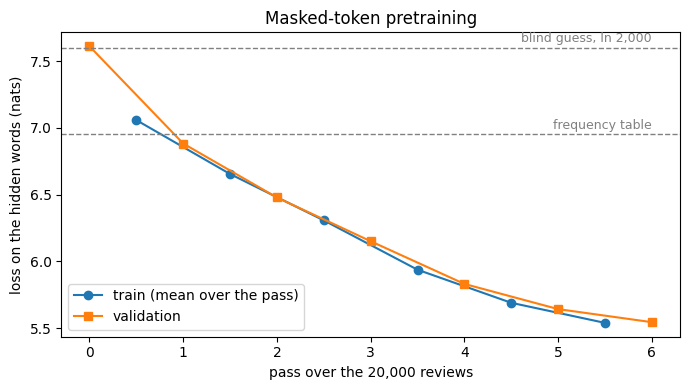

validation loss: 7.612 -> 5.545   (frequency table: 6.953)
perplexity: 2,022 -> 256   (frequency table: 1,046)
top guess right: 14.3%   (frequency table: 0.6%)


In [11]:
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, EPOCHS + 1) - 0.5, hist["train"], "o-", label="train (mean over the pass)")
plt.plot(hist["epoch"], hist["val"], "s-", label="validation")
for value, name in [(loss_blind, "blind guess, ln 2,000"), (loss_freq, "frequency table")]:
    plt.axhline(value, color="grey", linestyle="--", linewidth=1)
    plt.text(EPOCHS, value + 0.04, name, ha="right", fontsize=9, color="grey")
plt.xlabel("pass over the 20,000 reviews"); plt.ylabel("loss on the hidden words (nats)")
plt.title("Masked-token pretraining"); plt.legend(); plt.tight_layout(); plt.show()

print(f"validation loss: {first_loss:.3f} -> {final_val:.3f}   (frequency table: {loss_freq:.3f})")
print(f"perplexity: {np.exp(first_loss):,.0f} -> {np.exp(final_val):,.0f}   (frequency table: {np.exp(loss_freq):,.0f})")
print(f"top guess right: {final_acc:.1%}   (frequency table: {acc_freq:.1%})")

### Why we see this

The loss spends its first pass getting down to the frequency line: the cheapest thing to learn is which
content words are common. Then it goes on down, and from there every bit of progress is the model **using
the words around the blank**.

It ends far below the frequency table and far above zero. That is as it should be. Nobody can say for sure
which word was hidden in "one of the most [MASK] films i have seen". A good model spreads its belief over the
words that fit. Train and validation stay together: like TinyGPT, this model is underfitting.

---
## Step 12 - Read its guesses

Take reviews the model has never seen, hide one word, and print its five best guesses with their
probabilities.

> **Predict:** when the hidden word is `bad`, will the guesses be words that mean something like `bad`, or
> words that could stand in the same place in a sentence?

In [12]:
def guess(row, position, top=5):
    """Hide the word at `position` of `row`; return the model's `top` guesses as (word, probability)."""
    x = np.array(row)[None, :].copy()
    x[0, position] = MASK
    s = blank_model.predict_on_batch([x, np.full((1, K), position, dtype=np.int32)])[0, 0]
    p = np.exp(s - s.max()); p /= p.sum()
    best = np.argsort(-p)[:top]
    return [(id_to_word[int(i)], float(p[i])) for i in best], float(p[int(row[position])])


def find(word, lo=8, hi=56):
    """The first held-out review that has `word` somewhere in the middle."""
    for r, row in enumerate(X_held):
        hits = np.where(row[lo:hi] == word_to_id[word])[0]
        if len(hits):
            return r, lo + int(hits[0])


for word in ["bad", "funny", "acting", "love", "boring", "director"]:
    r, p = find(word)
    row = X_held[r]
    best, p_true = guess(row, p)
    print("...", decode(row[p - 7:p]), "[MASK]", decode(row[p + 1:p + 6]), "...")
    print(f"    hidden word: {word!r} (given probability {p_true:.1%})")
    print("    guesses    :", ", ".join(f"{w} {q:.0%}" for w, q in best))
    print()

... to start oh [?] message to the [MASK] guys when you first find ...
    hidden word: 'bad' (given probability 0.1%)
    guesses    : where 2%, life 2%, two 2%, people 2%, story 2%

... not think [?] something about mary was [MASK] so that [?] count except ...
    hidden word: 'funny' (given probability 1.8%)
    guesses    : very 3%, really 2%, funny 2%, much 1%, disappointed 1%

... this film had my heart [?] the [MASK] was great the [?] music ...
    hidden word: 'acting' (given probability 1.3%)
    guesses    : story 7%, first 5%, same 4%, plot 3%, best 2%

... [?] with the rating but i just [MASK] this movie i've seen it ...
    hidden word: 'love' (given probability 0.8%)
    guesses    : saw 17%, watched 10%, enjoyed 4%, rented 4%, thought 3%

... other [?] [?] that it is was [MASK] though i must say that ...
    hidden word: 'boring' (given probability 0.7%)
    guesses    : bad 4%, very 3%, really 2%, much 2%, pretty 2%

... badly edited 80's [?] horror masterpiece the [MAS

### Why we see this

The model is rarely right and rarely silly. After `i just ___ this movie` it offers `saw`, `watched`,
`enjoyed`, `rented`: all verbs, all things one does to a film. After `it is was ___ though` it offers `bad`,
`very`, `really`, `pretty`. It has learnt which **kind** of word fits a slot, from nothing but reviews with
holes in them. It is much less sure which word of that kind, and after two minutes of training it should not
be. The first example shows the other side: with little to go on (`the ___ guys`) its guesses are only common
words.

This model was never asked for a common word (`the`, `is`, `and`: Step 7), so it would do badly on those
blanks. And note what it cannot do at all: write. It can fill one blank given both sides. Nothing in its
training tells it how to produce a text from left to right (Chapter 36).

---
## Step 13 - What the token table learnt

The token table started as noise. Look up a few words and list their nearest neighbours by cosine similarity
(Chapter 18).

> **Predict:** will the neighbours of `terrible` be other words for bad things? Will `great` and `bad` be far
> apart?

In [13]:
table = encoder.get_layer("embed").token_table.get_weights()[0]
unit = table / np.linalg.norm(table, axis=1, keepdims=True)


def neighbours(word, top=6):
    sims = unit @ unit[word_to_id[word]]
    return [id_to_word[int(i)] for i in np.argsort(-sims)[1:top + 1]]


for word in ["terrible", "wonderful", "boring", "funny", "actor", "director", "great", "bad"]:
    print(f"{word:>10s} -> {', '.join(neighbours(word))}")
print()
print(f"cosine(great, bad)      = {float(unit[word_to_id['great']] @ unit[word_to_id['bad']]):+.2f}")
print(f"cosine(great, director) = {float(unit[word_to_id['great']] @ unit[word_to_id['director']]):+.2f}")

  terrible -> stupid, cool, awful, cheesy, incredibly, looked
 wonderful -> perfect, beautiful, excellent, unique, classic, successful
    boring -> bad, lame, ridiculous, pretty, dumb, terrible
     funny -> bad, really, better, much, plot, stupid
     actor -> director, character, music, role, man, fun
  director -> actor, book, part, novel, genre, great
     great -> very, horror, made, its, interesting, only
       bad -> funny, plot, much, boring, really, even

cosine(great, bad)      = +0.50
cosine(great, director) = +0.46


### Why we see this

Words that fill the same blanks end up close together. That gives tidy families (people who make films,
words of praise, words of complaint), and it also explains the embarrassments in the list: an opposite often
fills the same blank as the word itself ("the film was ___"), so opposites can sit closer together than you
would like. Blank-filling learns *what can stand here*. Whether that includes *what the reviewer felt* depends
on how much the surrounding words give away, and on how long you train.

---
## Step 14 - A sentiment classifier on top of the encoder

Now open the drawer with the labels. The classifier is:

1. the encoder (64 vectors of 64 numbers),
2. **one vector for the whole review**: the average of the 64 vectors,
3. a `Dense(1)` that turns that vector into a score: positive if above zero.

BERT took the vector at the first position (its `[CLS]` token) for step 2. Ours takes the average, because
nothing in our pretraining ever graded position 0. Trial 4 lets you try the first position.

The classifier has a little dropout (0.1), as fine-tuning usually does.

To compare starting points fairly we build the classifier **once** and write a function, `run()`, that puts it
back to a chosen starting point: the given encoder weights, a fresh small head, and an optimizer that
remembers nothing. (`build_classifier()` returns the classifier and its encoder body as a pair; the body is
the handle `run()` uses to set the encoder's weights.)

> **Predict:** how many parameters does the head add?

In [14]:
def build_classifier(freeze=False):
    """encoder -> average over positions -> Dense(1). freeze=True trains the head only."""
    body = build_encoder(dropout=0.1)
    body.trainable = not freeze
    pooled = layers.GlobalAveragePooling1D(name="average")(body.output)
    score = layers.Dense(1, name="head")(pooled)
    model = keras.Model(body.input, score, name="classifier")
    model.compile(optimizer=keras.optimizers.AdamW(1e-3, weight_decay=0.01, clipnorm=1.0),
                  loss=keras.losses.BinaryCrossentropy(from_logits=True),
                  metrics=[keras.metrics.BinaryAccuracy(threshold=0.0, name="accuracy")])
    return model, body                   # `body` shares its layers with `model`: a handle for setting weights


def random_weights(seed):
    """Encoder weights nobody has trained: what 'from scratch' starts from."""
    keras.utils.set_random_seed(seed)
    return build_encoder().get_weights()


def run(pair, start_weights, lr, n_labels, epochs, seed):
    """Put a (classifier, body) pair at a starting point, train on the first n_labels labelled reviews,
    return test and training accuracy."""
    model, body = pair
    keras.utils.set_random_seed(seed)
    body.set_weights(start_weights)
    head_start = np.random.default_rng(seed).normal(0, 0.05, size=(64, 1)).astype("float32")
    model.get_layer("head").set_weights([head_start, np.zeros(1, "float32")])
    for v in model.optimizer.variables:                    # forget Adam's averages and the step count
        v.assign(keras.ops.zeros_like(v))
    model.optimizer.learning_rate.assign(lr)
    model.fit(X_pre[:n_labels], y_pre[:n_labels], batch_size=32, epochs=epochs, verbose=0)
    train_acc = model.evaluate(X_pre[:n_labels], y_pre[:n_labels], batch_size=250, verbose=0)[1]
    test_acc = model.evaluate(X_test, y_test, batch_size=250, verbose=0)[1]
    return test_acc, train_acc


classifier = build_classifier()
n_trainable = sum(int(np.prod(w.shape)) for w in classifier[0].trainable_weights)
print(f"classifier: {classifier[0].count_params():,} parameters = encoder {hand_body:,} + head {64 + 1}")
assert classifier[0].count_params() == hand_body + 65 == n_trainable
print(f"test set: {len(X_test):,} reviews the pretraining never saw, {y_test.mean():.1%} positive")

classifier: 232,257 parameters = encoder 232,192 + head 65


test set: 4,000 reviews the pretraining never saw, 48.1% positive


---
## Step 15 - The experiment: 1,000 labels, two starting points

Imagine you could afford to label only **1,000** reviews. Train the classifier on them twice:

* **from scratch:** the encoder starts from random weights (learning rate 1e-3);
* **pretrained, then fine-tuned:** the encoder starts from the weights of Step 10 (learning rate 3e-4, three
  times smaller: the usual choice when the weights already hold something worth keeping; Chapter 39 explains,
  and Trial 6 lets you test it).

Same architecture, same 1,000 labels, same six passes, same test set. The only difference is where the
weights start. One run of each proves little (Chapter 12), so we do three, with three different seeds.

> **Predict:** the test accuracy of each. A coin scores 50%. And which will have the higher *training*
> accuracy?

In [15]:
N_LABELS, PASSES, SEEDS = 1000, 6, [0, 1, 2]
results = {}


def repeat(name, pair, weights_for, lr, n_labels=N_LABELS, epochs=PASSES, seeds=SEEDS):
    """Run one condition over several seeds, print it, remember it."""
    t0 = time.time()
    runs = [run(pair, weights_for(seed), lr, n_labels, epochs, seed) for seed in seeds]
    test = [r[0] for r in runs]
    results[(name, n_labels)] = test
    print(f"{name:34s} {n_labels:5,d} labels   test " + "  ".join(f"{a:.1%}" for a in test)
          + f"   mean {np.mean(test):.1%}   (train {np.mean([r[1] for r in runs]):.0%})   [{time.time() - t0:3.0f}s]")
    return float(np.mean(test))


scratch_1000 = repeat("from scratch", classifier, random_weights, 1e-3)
tuned_1000 = repeat("pretrained, fine-tuned", classifier, lambda seed: pretrained_weights, 3e-4)
print(f"\ngain from pretraining at 1,000 labels: {100 * (tuned_1000 - scratch_1000):+.1f} points")

from scratch                       1,000 labels   test 67.0%  65.1%  68.0%   mean 66.7%   (train 98%)   [ 38s]


pretrained, fine-tuned             1,000 labels   test 68.5%  70.5%  70.2%   mean 69.7%   (train 93%)   [ 23s]

gain from pretraining at 1,000 labels: +3.0 points


### Why we see this

Both classifiers are well above a coin and far below what a full-size system reaches on this data set (above
90%, with whole reviews, a real vocabulary and a pretrained model hundreds of times larger). Ours sees 64
words, knows 1,995 of them, and has 1,000 examples.

Within those limits the pretrained start wins by about three points on average. Look at the three seeds
before you believe it: runs that differ in nothing but their seed differ by two or three points, as much as
the gap being measured. One run of each could have shown anything. Three of each, all leaning the same way,
is the least you should accept.

Look at the training accuracies as well. From scratch, the network fits its 1,000 reviews almost perfectly:
it has 232,257 weights and nothing but those reviews to shape them, so it memorises. The pretrained network
arrives knowing which words behave alike, so 1,000 labels have less to teach it and less room to mislead it.

The gain is modest because the pretraining was two minutes long. Do not read its size as the size of the
effect in general. Read its **direction**.

---
## Step 16 - How much did pretraining already know? Freeze the encoder

A harder test of the pretrained weights: **do not train them at all**. Freeze the encoder and train only the
head, 65 weights, on the same 1,000 labels. The head can only draw a line through whatever the encoder
already puts in its average vector. (This is a *linear probe*; Chapter 39 calls the method feature extraction.)

Do it on the pretrained encoder (three seeds) and, as a control, on an encoder of random weights (one seed).

> **Predict:** which is higher: a frozen pretrained encoder with 65 trained weights, or the 232,257 weights
> trained from scratch in Step 15?

In [16]:
probe = build_classifier(freeze=True)
print("trainable weights in the probe:", sum(int(np.prod(w.shape)) for w in probe[0].trainable_weights))
frozen_pre = repeat("pretrained, frozen (head only)", probe, lambda seed: pretrained_weights, 1e-2)
frozen_rand = repeat("random, frozen (head only)", probe, random_weights, 1e-2, seeds=[0])

trainable weights in the probe: 65


pretrained, frozen (head only)     1,000 labels   test 66.8%  66.9%  66.2%   mean 66.6%   (train 68%)   [ 13s]


random, frozen (head only)         1,000 labels   test 57.4%   mean 57.4%   (train 60%)   [  4s]


### Why we see this

The frozen random encoder gets a little above a coin: an average of untrained vectors is a blurred bag of
words, and a few very telling words leak through. The frozen **pretrained** encoder is far better, with the
same 65 trainable weights. Everything in that gap was learnt from text without labels. Compare it with
Step 15's from-scratch number and you have the argument for pretraining in one line: what two minutes of
blank-filling learnt about reviews is worth about as much as training the whole network on 1,000 labels.

---
## Step 17 - More labels, fewer labels

Repeat the comparison with 250 labels and with 4,000 (one seed each, to stay inside the time budget; the
1,000-label points are the three-seed means of Step 15). The number of passes changes so that each run does
a similar amount of work.

> **Predict:** where is the gain from pretraining largest, in points: at 250, 1,000 or 4,000 labels?

from scratch                         250 labels   test 62.1%   mean 62.1%   (train 100%)   [  5s]


pretrained, fine-tuned               250 labels   test 68.5%   mean 68.5%   (train 100%)   [  5s]


from scratch                       4,000 labels   test 73.3%   mean 73.3%   (train 91%)   [ 13s]


pretrained, fine-tuned             4,000 labels   test 73.5%   mean 73.5%   (train 87%)   [ 13s]

  250 labels: from scratch 62.1%   pretrained 68.5%   gain +6.4 points
1,000 labels: from scratch 66.7%   pretrained 69.7%   gain +3.0 points
4,000 labels: from scratch 73.3%   pretrained 73.5%   gain +0.2 points


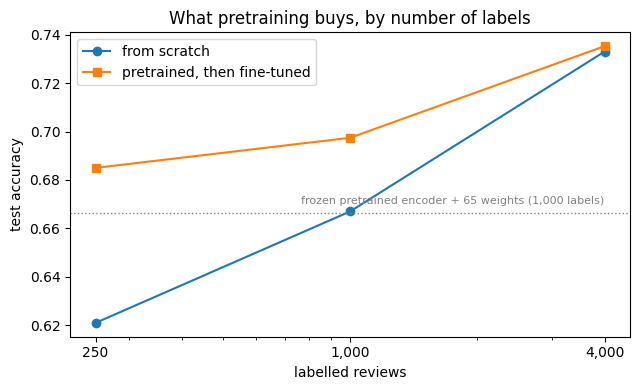

In [17]:
for n, passes in [(250, 12), (4000, 3)]:
    repeat("from scratch", classifier, random_weights, 1e-3, n_labels=n, epochs=passes, seeds=[0])
    repeat("pretrained, fine-tuned", classifier, lambda seed: pretrained_weights, 3e-4, n_labels=n, epochs=passes, seeds=[0])

sizes = [250, 1000, 4000]
curve_scratch = [float(np.mean(results[("from scratch", n)])) for n in sizes]
curve_tuned = [float(np.mean(results[("pretrained, fine-tuned", n)])) for n in sizes]
print()
for n, a, b in zip(sizes, curve_scratch, curve_tuned):
    print(f"{n:5,d} labels: from scratch {a:.1%}   pretrained {b:.1%}   gain {100 * (b - a):+.1f} points")

plt.figure(figsize=(6.5, 4))
plt.plot(sizes, curve_scratch, "o-", label="from scratch")
plt.plot(sizes, curve_tuned, "s-", label="pretrained, then fine-tuned")
plt.axhline(frozen_pre, color="grey", linestyle=":", linewidth=1)
plt.text(sizes[-1], frozen_pre + 0.004, "frozen pretrained encoder + 65 weights (1,000 labels)", ha="right", fontsize=8, color="grey")
plt.xscale("log"); plt.xticks(sizes, [f"{n:,}" for n in sizes])
plt.xlabel("labelled reviews"); plt.ylabel("test accuracy")
plt.title("What pretraining buys, by number of labels"); plt.legend(); plt.tight_layout(); plt.show()

### Why we see this

More labels help both, and the gap narrows as they do: it is widest at 250 labels and small by 4,000. That is
the pattern to remember. **Pretraining matters most when labels are scarce.** With enough labels a model this
small learns from the labels themselves what the pretraining knew.

Read the plot sideways too. The pretrained model with 250 labels is level with the from-scratch model with
1,000: four times fewer labels for the same accuracy. Labels cost money and patience; unlabelled text costs
neither. That exchange rate is the business case for pretraining.

The single-seed points wobble by a point or two (Step 15 showed how much seeds differ), so do not read
anything into small differences.

---
## Step 18 - How much signal per sequence?

The masked model read 64 tokens per sequence and was graded on 9. A causal model reading the same 64 tokens
is graded on 63 (every position has a next token except the last).

> **Predict:** over the whole pretraining, how many graded questions did our masked model answer? How many
> would a causal model have answered on the same text, in the same number of passes?

In [18]:
sequences = EPOCHS * len(X_pre)
masked_q = sequences * K
causal_q = sequences * (T - 1)
print(f"sequences read in pretraining: {sequences:,}  ({sequences * T:,} tokens)")
print(f"masked model: {K} graded positions per sequence  = {masked_q:>9,} questions  ({K / T:.1%} of positions)")
print(f"causal model: {T - 1} graded positions per sequence = {causal_q:>9,} questions  ({(T - 1) / T:.1%} of positions)")
print(f"ratio: {causal_q / masked_q:.0f} times")

sequences read in pretraining: 120,000  (7,680,000 tokens)
masked model: 9 graded positions per sequence  = 1,080,000 questions  (14.1% of positions)
causal model: 63 graded positions per sequence = 7,560,000 questions  (98.4% of positions)
ratio: 7 times


### Why we see this

Per pass over the text, a causal model gets seven times as many graded questions from the same reading. The
masked model's questions are richer (it sees both sides of every blank), but there are far fewer of them. This
is one of the reasons the causal family scaled so well (Chapter 38): every token of the corpus is a training
signal.

---
## Step 19 - From this encoder to BERT-base

BERT-base (2018): 12 blocks, width 768, feed-forward 3,072, 512 positions, a WordPiece vocabulary of 30,522.
Its inventory has four items ours does not: a **segment table** (2 rows: "first sentence" or "second
sentence"), a LayerNorm straight after the tables, no final LayerNorm (its blocks normalise *after* each
sub-layer, the post-norm layout of Chapter 23, so each block still has two LayerNorms), and a **pooler**, a
d × d dense layer applied to the first position's vector.

> **Predict:** "about 110 million". Which is bigger in BERT-base: the token table, or one block?

In [19]:
def count_bert(vocab_size=30522, d=768, blocks=12, ff=3072, positions=512, segments=2):
    attention = 4 * d * d + 4 * d
    feed_forward = (d * ff + ff) + (ff * d + d)
    one_block = attention + feed_forward + 2 * (2 * d)
    parts = {"token table": vocab_size * d, "position table": positions * d, "segment table": segments * d,
             "norm after the tables": 2 * d, "blocks": blocks * one_block, "pooler": d * d + d}
    return parts, one_block


bert_parts, bert_block = count_bert()
bert_total = sum(bert_parts.values())
for name, n in bert_parts.items():
    print(f"  {name:22s} {n:>12,}   {n / bert_total:6.1%}")
print(f"  {'BERT-base TOTAL':22s} {bert_total:>12,}")
print(f"  one block: {bert_block:,}  (the same count as one block of GPT-2 small)")
assert bert_total == 109_482_240 and bert_block == 7_087_872
print(f"\nBERT-base is {bert_total / hand_body:,.0f} times our encoder")
print(f"float32 size: {bert_total * 4 / 1e6:,.0f} MB")
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

  token table              23,440,896    21.4%
  position table              393,216     0.4%
  segment table                 1,536     0.0%
  norm after the tables         1,536     0.0%
  blocks                   85,054,464    77.7%
  pooler                      590,592     0.5%
  BERT-base TOTAL         109,482,240
  one block: 7,087,872  (the same count as one block of GPT-2 small)

BERT-base is 472 times our encoder
float32 size: 438 MB

whole notebook: 267 s


### Why we see this

109,482,240: the "about 110 million" of every BERT table. One block of BERT-base has exactly as many weights
as one block of GPT-2 small (7,087,872), because it *is* the same block at the same width. What differs
between the two models is the mask, the question asked in pretraining, and a few small tables.

What does not scale from this notebook is the pretraining: about 3.3 billion words (BooksCorpus and English
Wikipedia) instead of our 1.3 million tokens, a million update steps instead of a few hundred, days on
specialised hardware instead of two minutes on a laptop.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 7: `N_COMMON = 0` (choose among all words, as BERT did), then rerun from Step 7 | Does the pretraining loss end lower or higher? Does the gain in Step 15 grow or shrink? | |
| 2 | Step 7: replace 80 / 10 / 10 by 100% mask tokens (`dice < 1.0`) | Does the frozen probe of Step 16 get better or worse? | |
| 3 | Step 10: `EPOCHS = 12` | Does the validation loss still fall? Does the gain at 1,000 labels grow? | |
| 4 | Step 14: use the first position, `body.output[:, 0]`, in place of the average | Which is better here, and why would BERT's answer differ? | |
| 5 | Step 7: `K = 19` (30% of positions) | More questions per sequence, less context per question. Which wins in two minutes? | |
| 6 | Step 15: fine-tune at 1e-4, then at 3e-3 | Where is the best rate? What happens far above it? | |
| 7 | Step 5: `build_encoder(blocks=1)` everywhere | Parameter count first. How much pretraining gain is lost? | |
| 8 | Step 18: add 16,000 labels (2 passes) | Does the gap between the two curves close? | |

---
## Exercises

1. **A causal body as a classifier.** Pretrain `build_encoder(causal=True)` with next-token prediction on the
   same text (inputs `x[:, :-1]`, targets `x[:, 1:]`, the untied or tied head at every position), then
   fine-tune it for sentiment using (a) the average vector and (b) the vector at the **last** position. Explain
   why the last position is the only one that has seen the whole review, and compare with the encoder.
2. **Padding.** Keep the reviews shorter than 64 tokens by padding them on the right with id 0. Pass an
   attention mask to `MultiHeadAttention` so that nobody looks at the padding, and leave padded positions out
   of the average. What happens to the accuracy if you forget either?
3. **Two blanks at once.** Hide two neighbouring words and print the model's top guess for each. Are the two
   guesses a sensible pair? Explain why a model that fills each blank on its own cannot be trusted to write.
4. **Segments.** Add a segment table with 2 rows and feed the model two half-reviews of 32 tokens. Train it to
   say whether the second half belongs to the same review as the first (next-sentence prediction). Is the
   task hard enough to teach anything?
5. **Sentence vectors.** Use the average vector of the pretrained (not fine-tuned) encoder as a 64-number
   summary of a review. For a few reviews, list the nearest other reviews by cosine similarity. Are they
   similar in subject, in sentiment, or only in length and common words?
6. **Hand-count RoBERTa-base.** It has BERT-base's blocks, a vocabulary of 50,265, 514 positions and 1 segment
   row. How many parameters, with the pooler? Which part changed most?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Encoder vs decoder body | the same block; `use_causal_mask=False` vs `True` |
| Open cells, T = 64 | full mask 4,096; causal mask 2,080 |
| Which mask does it have? | change one token: an encoder moves every output, a decoder only those from there on |
| Masked-token prediction | choose 15% of positions; of those 80% → mask token, 10% → random word, 10% → unchanged; predict the original |
| Why 80 / 10 / 10 | the mask token never appears at fine-tune time, so the model must not rely on it |
| Graded positions | only the chosen ones: here 9 of 64 |
| First loss | ≈ ln V = ln 2,000 = 7.601 |
| Blank-filling head | applied at the chosen positions only; tied to the token table (adds V biases) |
| This lab's encoder | d = 64, 4 heads, 2 blocks, ff = 256, T = 64, V = 2,000: 232,192 parameters |
| Classifier | encoder → one vector (average, or first position) → `Dense(1)`: + 65 parameters |
| Fine-tuning | start from pretrained weights, smaller learning rate than from scratch |
| Linear probe | freeze the encoder, train the head: measures what pretraining already knows |
| Signal per sequence | masked: about 15% of positions; causal: all of them |
| BERT-base (2018) | 12 blocks, d = 768, 512 positions, V = 30,522: 109,482,240 parameters |